In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


### Explanation:
This cell imports essential Python libraries for data manipulation and visualization:
- `pandas` as `pd`: Used for data manipulation and analysis, especially with DataFrames.
- `matplotlib.pyplot` as `plt`: Used for creating static, interactive, and animated visualizations in Python.
- `seaborn` as `sns`: A data visualization library based on matplotlib, providing a high-level interface for drawing attractive and informative statistical graphics.
- `numpy` as `np`: Used for numerical operations, especially with arrays and mathematical functions.

In [ ]:
import kagglehub
import os
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("sudalairajkumar/indian-startup-funding")

print("Path to dataset files:", path)

df=pd.read_csv(os.path.join(path,"startup_funding.csv"))
df.head()

100%|██████████| 120k/120k [00:00<00:00, 19.0MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sudalairajkumar/indian-startup-funding/versions/4


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN


### Explanation:
This cell handles the downloading and initial loading of the dataset:
- `import kagglehub`: Imports the KaggleHub library to interact with Kaggle datasets.
- `import os`: Imports the operating system module, used here for path manipulation.
- `path = kagglehub.dataset_download("sudalairajkumar/indian-startup-funding")`: Downloads the specified Kaggle dataset and stores its local path in the `path` variable.
- `print("Path to dataset files:", path)`: Prints the local path where the dataset files are stored.
- `df = pd.read_csv(os.path.join(path,"startup_funding.csv"))`: Reads the `startup_funding.csv` file from the downloaded path into a pandas DataFrame named `df`.
- `df.head()`: Displays the first 5 rows of the DataFrame, giving a quick overview of the data structure and content.

In [ ]:
df.shape

(3044, 10)

### Explanation:
- `df.shape`: This command returns a tuple representing the dimensionality of the DataFrame. The output `(3044, 10)` means the DataFrame has 3044 rows and 10 columns.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Sr No              3044 non-null   int64 
 1   Date dd/mm/yyyy    3044 non-null   object
 2   Startup Name       3044 non-null   object
 3   Industry Vertical  2873 non-null   object
 4   SubVertical        2108 non-null   object
 5   City  Location     2864 non-null   object
 6   Investors Name     3020 non-null   object
 7   InvestmentnType    3040 non-null   object
 8   Amount in USD      2084 non-null   object
 9   Remarks            419 non-null    object
dtypes: int64(1), object(9)
memory usage: 237.9+ KB


### Explanation:
- `df.info()`: This method prints a concise summary of the DataFrame, including:
    - The number of entries (rows).
    - The total number of columns.
    - A list of all columns with their non-null count and data type (`Dtype`).
    - Memory usage.
This output helps identify columns with missing values and understand the data types, which is crucial for data cleaning.

In [ ]:
df.isnull().sum()

,0
Sr No,0
Date dd/mm/yyyy,0
Startup Name,0
Industry Vertical,171
SubVertical,936
City Location,180
Investors Name,24
InvestmentnType,4
Amount in USD,960
Remarks,2625


### Explanation:
- `df.isnull().sum()`: This command first checks for null (missing) values in each cell of the DataFrame (`df.isnull()`), then sums up the `True` values (which represent nulls) for each column. The result shows the total count of missing values for every column, highlighting areas that need imputation or removal.

In [ ]:
df.duplicated().sum()


np.int64(0)

### Explanation:
- `df.duplicated().sum()`: This command identifies duplicate rows in the DataFrame. `df.duplicated()` returns a boolean Series indicating whether each row is a duplicate of a previous row. `.sum()` then counts the number of `True` values, which represents the total number of duplicate rows. An output of `np.int64(0)` means there are no duplicate rows in the DataFrame at this stage.

In [ ]:
df.columns

Index(['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical',
       'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType',
       'Amount in USD', 'Remarks'],
      dtype='object')

### Explanation:
- `df.columns`: This attribute returns an Index object containing the labels of the columns in the DataFrame. It's used to inspect the current column names, which is a common first step before renaming them for consistency or ease of use.

In [ ]:
df["Startup Name"].unique()

array(['BYJU’S', 'Shuttl', 'Mamaearth', ..., 'Graphene', 'Simplotel',
       'couponmachine.in'], dtype=object)

### Explanation:
- `df["Startup Name"].unique()`: This command selects the 'Startup Name' column and then applies the `.unique()` method, which returns an array of all unique values present in that column. This helps in understanding the variety and potential inconsistencies (like different spellings or formatting) in startup names before cleaning.

In [ ]:
df.rename(columns={'Sr No':'Sr_No',
                   'Date dd/mm/yyyy':'Date',
                   'Startup Name':'Startup_Name',
                   'Industry Vertical':'Industry',
                   'SubVertical':'Sub_Vertical',
                   'City  Location':'City',
                   'Investors Name':'Investors',
                   'InvestmentnType':'Investment_Type',
                   'Amount in USD': 'Funding_USD',
                   'Remarks':'Remarks'
                  } , inplace=True)

### Explanation:
- `df.rename(columns={...}, inplace=True)`: This method is used to rename columns in the DataFrame. A dictionary is passed where keys are the old column names and values are the new column names. `inplace=True` ensures that the changes are applied directly to the DataFrame `df` without creating a new DataFrame.

In [ ]:
df.columns

Index(['Sr_No', 'Date', 'Startup_Name', 'Industry', 'Sub_Vertical', 'City',
       'Investors', 'Investment_Type', 'Funding_USD', 'Remarks'],
      dtype='object')

### Explanation:
- `df.columns`: After renaming, this command is used again to display the column names, confirming that the renaming operation in the previous cell was successful and the new standardized names (`Sr_No`, `Date`, `Startup_Name`, etc.) are now in place.

In [ ]:
df['Date'] = df['Date'].replace({'05/072018': '05/07/2018',
                                     '01/07/015': '01/07/2015',
                                     r'\\xc2\\xa010/7/2015': '01/07/2015',
                                     '12/05.2015': '02/05/2015',
                                     '13/04.2015': '13/04/2015',
                                     '15/01.2015': '15/01/2015',
                                     '22/01//2015': '22/01/2015'})
df['Date'] = pd.to_datetime(df['Date'],format="%d/%m/%Y")


### Explanation:
This cell is dedicated to cleaning and converting the `Date` column:
- `df['Date'] = df['Date'].replace({...})`: This line uses a dictionary to replace specific malformed date strings with their correct format. For example, `'05/072018'` is corrected to `'05/07/2018'`, and other similar errors are addressed.
- `df['Date'] = pd.to_datetime(df['Date'],format="%d/%m/%Y")`: This is a crucial step. It converts the `Date` column to pandas `datetime` objects. `format="%d/%m/%Y"` explicitly tells pandas the expected format of the date strings (day/month/year), which helps in correctly parsing the dates. Any values that cannot be parsed according to this format might become `NaT` (Not a Time) but this specific command will raise an error if not all values conform. The previous `.replace()` helps ensure consistency before this step.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Sr_No            3044 non-null   int64         
 1   Date             3044 non-null   datetime64[ns]
 2   Startup_Name     3044 non-null   object        
 3   Industry         2873 non-null   object        
 4   Sub_Vertical     2108 non-null   object        
 5   City             2864 non-null   object        
 6   Investors        3020 non-null   object        
 7   Investment_Type  3040 non-null   object        
 8   Funding_USD      2084 non-null   object        
 9   Remarks          419 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(8)
memory usage: 237.9+ KB


### Explanation:
- `df.info()`: This command is run again to confirm the changes after the date cleaning. It shows that the `Date` column's `Dtype` has successfully changed from `object` to `datetime64[ns]`, indicating that the dates are now stored in a proper datetime format, which is essential for time-series analysis.

In [ ]:
df.drop(columns = 'Remarks',axis=1,inplace=True)


### Explanation:
- `df.drop(columns = 'Remarks',axis=1,inplace=True)`: This command drops the 'Remarks' column from the DataFrame. `axis=1` specifies that a column is being dropped, and `inplace=True` modifies the DataFrame directly. This decision was likely made because the `df.isnull().sum()` output earlier showed that the 'Remarks' column had a very high number of missing values (2625 out of 3044), making it unsuitable for analysis.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Sr_No            3044 non-null   int64         
 1   Date             3044 non-null   datetime64[ns]
 2   Startup_Name     3044 non-null   object        
 3   Industry         2873 non-null   object        
 4   Sub_Vertical     2108 non-null   object        
 5   City             2864 non-null   object        
 6   Investors        3020 non-null   object        
 7   Investment_Type  3040 non-null   object        
 8   Funding_USD      2084 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(7)
memory usage: 214.2+ KB


### Explanation:
- `df.info()`: This command is executed again to verify the DataFrame structure after dropping the 'Remarks' column. The output confirms that the 'Remarks' column is no longer present, and the DataFrame now has 9 columns instead of 10.

In [ ]:
df['Funding_USD'].head(200)

,Funding_USD
0,"20,00,00,000"
1,"80,48,394"
2,"1,83,58,860"
3,"30,00,000"
4,"18,00,000"
...,...
195,"11,00,000"
196,"4,37,000"
197,NaN
198,"50,00,000"


### Explanation:
- `df['Funding_USD'].head(200)`: This command displays the first 200 entries of the `Funding_USD` column. It's used to inspect the raw format of the funding amounts, which are currently `object` (string) type and contain commas, 'undisclosed', 'unknown', and `NaN` values, indicating that cleaning is needed before numerical operations can be performed.

In [ ]:
# Ensure Funding_USD is string type for .str operations
df['Funding_USD'] = df['Funding_USD'].astype(str)

# Replace 'undisclosed', 'unknown', and 'nan' strings (case-insensitive) with '0'
df['Funding_USD'] = df['Funding_USD'].str.lower().replace(['undisclosed', 'unknown', 'nan'], '0', regex=False)

# Remove commas from the string values
df['Funding_USD'] = df['Funding_USD'].str.replace(',', '', regex=False)

# Convert the cleaned string column to numeric, coercing any remaining errors to NaN
df['Funding_USD'] = pd.to_numeric(df['Funding_USD'], errors='coerce')

# Fill any NaN values (either original or from coercion) with 0
df['Funding_USD'] = df['Funding_USD'].fillna(0)


### Explanation:
This cell performs a series of steps to clean and convert the `Funding_USD` column into a usable numeric format:
1.  `df['Funding_USD'] = df['Funding_USD'].astype(str)`: Ensures the column is treated as strings, allowing string manipulation methods.
2.  `df['Funding_USD'] = df['Funding_USD'].str.lower().replace(['undisclosed', 'unknown', 'nan'], '0', regex=False)`: Converts all values to lowercase and replaces non-numeric strings like 'undisclosed', 'unknown', and string representations of `NaN` with '0'. `regex=False` ensures exact string matching.
3.  `df['Funding_USD'] = df['Funding_USD'].str.replace(',', '', regex=False)`: Removes commas from the string to prepare for numeric conversion.
4.  `df['Funding_USD'] = pd.to_numeric(df['Funding_USD'], errors='coerce')`: Converts the cleaned string column to a numeric type (`float`). `errors='coerce'` is crucial here: any values that still cannot be converted to numbers (after previous cleaning) will be turned into `NaN` (Not a Number).
5.  `df['Funding_USD'] = df['Funding_USD'].fillna(0)`: Fills any remaining `NaN` values (those that were originally `NaN` or became `NaN` due to `errors='coerce'`) with `0`. This ensures the column is entirely numeric with no missing values.

In [ ]:
def dollar_to_rupee(dollar):
    inr = dollar*94.49
    return round(inr/10000000,2)

df['amount_inr_cr'] = df['Funding_USD'].apply(dollar_to_rupee)


### Explanation:
This cell defines a function to convert USD to INR (in crores) and applies it to create a new column:
- `def dollar_to_rupee(dollar):`: Defines a function named `dollar_to_rupee` that takes a `dollar` amount as input.
- `inr = dollar*94.49`: Converts the dollar amount to Indian Rupees using an assumed exchange rate of 1 USD = 94.49 INR.
- `return round(inr/10000000,2)`: Converts the INR amount into crores (1 crore = 10,000,000) and rounds it to 2 decimal places.
- `df['amount_inr_cr'] = df['Funding_USD'].apply(dollar_to_rupee)`: Creates a new column named `amount_inr_cr` by applying the `dollar_to_rupee` function to each value in the `Funding_USD` column. This provides an equivalent funding amount in Indian Rupees (crores).

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Sr_No            3044 non-null   int64         
 1   Date             3044 non-null   datetime64[ns]
 2   Startup_Name     3044 non-null   object        
 3   Industry         2873 non-null   object        
 4   Sub_Vertical     2108 non-null   object        
 5   City             2864 non-null   object        
 6   Investors        3020 non-null   object        
 7   Investment_Type  3040 non-null   object        
 8   Funding_USD      3044 non-null   float64       
 9   amount_inr_cr    3044 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(6)
memory usage: 237.9+ KB


### Explanation:
- `df.info()`: This command is run again to check the DataFrame's structure after the currency conversion. It confirms that a new column, `amount_inr_cr`, has been added and both `Funding_USD` and `amount_inr_cr` columns are now of a numeric type (`float64`), and importantly, they have no non-null counts, indicating no missing values.

In [ ]:
df.head()

,Sr_No,Date,Startup_Name,Industry,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,amount_inr_cr
0,1,2020-01-09,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,200000000.0,1889.80
1,2,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,8048394.0,76.05
2,3,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,18358860.0,173.47
3,4,2020-01-02,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,3000000.0,28.35
4,5,2020-01-02,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,1800000.0,17.01


### Explanation:
- `df.head()`: This displays the first 5 rows of the DataFrame, allowing a visual check of the `Funding_USD` and `amount_inr_cr` columns to ensure the cleaning and conversion were successful and the values look reasonable.

In [ ]:
df = df.dropna(subset=['Date', 'Startup_Name', 'Industry', 'City', 'Investors', 'Investment_Type', 'Funding_USD'])

### Explanation:
- `df = df.dropna(subset=['Date', 'Startup_Name', 'Industry', 'City', 'Investors', 'Investment_Type', 'Funding_USD'])`: This command removes rows from the DataFrame where any of the specified columns (`Date`, `Startup_Name`, `Industry`, `City`, `Investors`, `Investment_Type`, `Funding_USD`) have missing (NaN) values. This is a critical step for ensuring that primary analysis columns contain complete data. The DataFrame `df` is then reassigned with these cleaned rows.

In [ ]:
df.set_index('Sr_No',inplace=True)


### Explanation:
- `df.set_index('Sr_No',inplace=True)`: This command sets the 'Sr_No' column as the new index of the DataFrame. `inplace=True` modifies the DataFrame directly. Using a unique identifier like 'Sr_No' as an index can sometimes facilitate data retrieval and management, although it was later reset.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2836 entries, 1 to 2873
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             2836 non-null   datetime64[ns]
 1   Startup_Name     2836 non-null   object        
 2   Industry         2836 non-null   object        
 3   Sub_Vertical     2080 non-null   object        
 4   City             2836 non-null   object        
 5   Investors        2836 non-null   object        
 6   Investment_Type  2836 non-null   object        
 7   Funding_USD      2836 non-null   float64       
 8   amount_inr_cr    2836 non-null   float64       
dtypes: datetime64[ns](1), float64(2), object(6)
memory usage: 221.6+ KB


### Explanation:
- `df.info()`: This is run again to show the DataFrame's summary after dropping rows with nulls and setting the index. It confirms the reduced number of entries (rows) and the new index type, along with updated non-null counts for all columns.

In [ ]:
df.duplicated().sum()

np.int64(0)

### Explanation:
- `df.duplicated().sum()`: This command checks for duplicate rows again after previous cleaning steps (like dropping rows with nulls). The output `np.int64(0)` confirms that there are still no duplicate rows in the DataFrame.

In [ ]:
import re

# Convert to string type to handle various inputs consistently
df['Startup_Name'] = df['Startup_Name'].astype(str)

# Convert to lowercase first for consistent URL matching
df['Startup_Name'] = df['Startup_Name'].str.lower()

# Replace URLs with 'unknown'
df['Startup_Name'] = df['Startup_Name'].replace(r'https?://\S+|www\.\S+', 'unknown', regex=True)

# Correct specific misspellings
df['Startup_Name'] = df['Startup_Name'].replace('fashor', 'Fashion', regex=False)


# Remove leading/trailing spaces and convert to title case
df['Startup_Name'] = df['Startup_Name'].str.strip().str.title()

# Display unique startup names after refined cleaning
print("Unique startup names (first 30 after refined cleaning):\n", df['Startup_Name'].unique()[:30])

Unique startup names (first 30 after refined cleaning):
 ['Byju’S' 'Shuttl' 'Mamaearth' 'Unknown' 'Fashion' 'Pando' 'Zomato'
 'Ecozen' 'Cardekho' 'Dhruva Space' 'Rivigo' 'Healthians' 'Licious'
 'Trell' 'Rein Games' 'Lenskart.Com' 'Freshworks' 'Misters'
 'Sunstone Eduversity Pvt. Ltd' 'Burger Singh' 'Ninjacart' 'Aye Finance'
 'Supergaming' 'Clumio' 'Ebikego' 'Digital Mall Asia' 'Medikabazaar'
 'Vogo Automotive' 'Paytm' 'Dunzo']


### Explanation:
This cell performs a comprehensive cleaning of the `Startup_Name` column:
1.  `import re`: Imports the regular expression module, though not explicitly used in the current version of this cell, it was probably there for earlier regex attempts.
2.  `df['Startup_Name'] = df['Startup_Name'].astype(str)`: Ensures all startup names are treated as strings.
3.  `df['Startup_Name'] = df['Startup_Name'].str.lower()`: Converts all startup names to lowercase for case-insensitive processing.
4.  `df['Startup_Name'] = df['Startup_Name'].replace(r'https?://\S+|www\.\S+', 'unknown', regex=True)`: Uses a regular expression to find and replace any URLs within the startup names with the string 'unknown'.
5.  `df['Startup_Name'] = df['Startup_Name'].replace('fashor', 'Fashion', regex=False)`: Corrects a specific misspelling, changing 'fashor' to 'Fashion'.
6.  `df['Startup_Name'] = df['Startup_Name'].str.strip().str.title()`:
    - `str.strip()`: Removes any leading or trailing whitespace from the startup names.
    - `str.title()`: Converts the first letter of each word in the startup name to uppercase and the rest to lowercase, ensuring consistent capitalization (e.g., 'byju’s' becomes 'Byju’S').
7.  `print("Unique startup names (first 30 after refined cleaning):\n", df['Startup_Name'].unique()[:30])`: Displays the first 30 unique startup names after all these cleaning steps, allowing a quick check of the cleaned data.

In [ ]:
df.head()

,Date,Startup_Name,Industry,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,amount_inr_cr
Sr_No,,,,,,,,,
1,2020-01-09,Byju’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,200000000.0,1889.80
2,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,8048394.0,76.05
3,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,18358860.0,173.47
4,2020-01-02,Unknown,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,3000000.0,28.35
5,2020-01-02,Fashion,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,1800000.0,17.01


### Explanation:
- `df.head()`: This command displays the first 5 rows of the DataFrame again. It's used here to show the DataFrame's state after the `Startup_Name` column has been thoroughly cleaned and formatted, allowing for visual confirmation of the changes.

In [ ]:
# Reset the index and drop the former 'Sr_No' column
df.reset_index(drop=True, inplace=True)

# Display the first few rows to confirm the change
display(df.head())

,Date,Startup_Name,Industry,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,amount_inr_cr
0,2020-01-09,Byju’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,200000000.0,1889.80
1,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,8048394.0,76.05
2,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,18358860.0,173.47
3,2020-01-02,Unknown,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,3000000.0,28.35
4,2020-01-02,Fashion,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,1800000.0,17.01


### Explanation:
- `df.reset_index(drop=True, inplace=True)`: This command resets the DataFrame's index. Since 'Sr_No' was previously set as the index, this action converts the current index back to a default integer index (0, 1, 2...). `drop=True` ensures that the old index ('Sr_No') is completely discarded and not added as a regular column. `inplace=True` applies the changes directly to `df`.
- `display(df.head())`: Displays the first few rows of the DataFrame, showing the newly reset default integer index.

The `df.reset_index(drop=True, inplace=True)` command was used to:
*   **`reset_index()`**: Convert the current index (`Sr_No`) back into a regular column.
*   **`drop=True`**: Prevent `Sr_No` from being added as a regular column after resetting the index; it's discarded instead.
*   **`inplace=True`**: Apply the changes directly to the DataFrame `df` without needing to assign the result to a new DataFrame.

### Explanation:
The `df.reset_index(drop=True, inplace=True)` command was used to:
*   **`reset_index()`**: Convert the current index (`Sr_No`) back into a regular column.
*   **`drop=True`**: Prevent `Sr_No` from being added as a regular column after resetting the index; it's discarded instead.
*   **`inplace=True`**: Apply the changes directly to the DataFrame `df` without needing to assign the result to a new DataFrame.

In [ ]:
# Display DataFrame information after cleaning
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2836 entries, 0 to 2835
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             2836 non-null   datetime64[ns]
 1   Startup_Name     2836 non-null   object        
 2   Industry         2836 non-null   object        
 3   Sub_Vertical     2080 non-null   object        
 4   City             2836 non-null   object        
 5   Investors        2836 non-null   object        
 6   Investment_Type  2836 non-null   object        
 7   Funding_USD      2836 non-null   float64       
 8   amount_inr_cr    2836 non-null   float64       
dtypes: datetime64[ns](1), float64(2), object(6)
memory usage: 199.5+ KB


### Explanation:
- `df.info()`: This command displays the DataFrame's summary again, specifically after resetting the index. It confirms that the `Sr_No` column is no longer the index and the DataFrame has a default `RangeIndex` (0 to 2835), along with the updated column types and non-null counts.

In [ ]:
# Display null values count for each column to verify cleanliness
df.isnull().sum()

,0
Date,0
Startup_Name,0
Industry,0
Sub_Vertical,756
City,0
Investors,0
Investment_Type,0
Funding_USD,0
amount_inr_cr,0


### Explanation:
- `df.isnull().sum()`: This command is used to display the count of null values for each column. At this stage, it shows that all columns except `Sub_Vertical` have 0 null values, confirming the effectiveness of the earlier data cleaning steps (dropping rows with nulls in key columns, filling nulls in `Funding_USD`). The `Sub_Vertical` column still has 756 nulls, which implies it might be handled differently or left as is, depending on the analysis goals.

In [ ]:
df.head()

,Date,Startup_Name,Industry,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,amount_inr_cr
0,2020-01-09,Byju’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,200000000.0,1889.80
1,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,8048394.0,76.05
2,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,18358860.0,173.47
3,2020-01-02,Unknown,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,3000000.0,28.35
4,2020-01-02,Fashion,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,1800000.0,17.01


### Explanation:
- `df.head()`: This command displays the first 5 rows of the DataFrame to provide a final visual check of the data after most of the cleaning and preprocessing steps. It shows the `Date`, cleaned `Startup_Name`, `Industry`, `Sub_Vertical`, `City`, `Investors`, `Investment_Type`, `Funding_USD`, and `amount_inr_cr` columns, all in their cleaned and processed state.

### Explanation:
This cell was previously used to filter and display data for a specific startup named 'Fashor'. However, it was subsequently cleared (its content is now empty), indicating that the specific filtering task it performed is no longer active or has been replaced by a more general approach, or the data needed to be re-filtered after the `Startup_Name` column was further modified. It currently serves no function.

In [ ]:
df['Startup_Name'] = df['Startup_Name'].replace('Unknown', 'Wealth Bucket', regex=False)

### Explanation:
- `df['Startup_Name'] = df['Startup_Name'].replace('Unknown', 'Wealth Bucket', regex=False)`: This command replaces all occurrences of the string 'Unknown' in the `Startup_Name` column with 'Wealth Bucket'. This is a specific data correction, likely addressing a situation where 'Unknown' was not meant to represent a truly unknown startup but rather a specific entity that was initially mislabeled or had a URL that was previously converted to 'unknown' and now needs a proper name.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2836 entries, 0 to 2835
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             2836 non-null   datetime64[ns]
 1   Startup_Name     2836 non-null   object        
 2   Industry         2836 non-null   object        
 3   Sub_Vertical     2080 non-null   object        
 4   City             2836 non-null   object        
 5   Investors        2836 non-null   object        
 6   Investment_Type  2836 non-null   object        
 7   Funding_USD      2836 non-null   float64       
 8   amount_inr_cr    2836 non-null   float64       
dtypes: datetime64[ns](1), float64(2), object(6)
memory usage: 199.5+ KB


In [ ]:
df.isnull().sum()

,0
Date,0
Startup_Name,0
Industry,0
Sub_Vertical,756
City,0
Investors,0
Investment_Type,0
Funding_USD,0
amount_inr_cr,0


In [ ]:
df['Sub_Vertical'].isnull().sum()

np.int64(756)

In [ ]:
df['Sub_Vertical'].fillna('Unknown', inplace=True)

### Explanation:
- `df['Sub_Vertical'].fillna('Unknown', inplace=True)`: This command fills all `NaN` (null) values in the `Sub_Vertical` column with the string 'Unknown'. The `inplace=True` argument ensures that the changes are applied directly to the DataFrame `df`.




Initially, the Sub_Vertical column had 756 missing (null) values. To handle these, we chose to fill them with the string 'Unknown'. This approach was taken to:

Retain data: Instead of dropping rows with missing sub-verticals, which could lead to significant data loss, we kept them.
Explicitly mark missingness: By using 'Unknown', we created a distinct category that clearly indicates where the sub-vertical information was not available, allowing for later analysis of 'unknown' sub-verticals if needed.
Avoid data distribution bias: Filling with the most frequent category (mode) could have skewed the distribution of sub-verticals, especially with such a large number of missing values. 'Unknown' provides a neutral alternative

In [ ]:
df.columns

Index(['Date', 'Startup_Name', 'Industry', 'Sub_Vertical', 'City', 'Investors',
       'Investment_Type', 'Funding_USD', 'amount_inr_cr'],
      dtype='object')

In [ ]:
df['Year'] = df['Date'].dt.year
funding_by_year = df.groupby('Year')['Funding_USD'].sum().reset_index()

### Explanation:
- `df['Year'] = df['Date'].dt.year`: This line extracts the year from the `Date` column (which is in datetime format) and creates a new column named `Year`.
- `funding_by_year = df.groupby('Year')['Funding_USD'].sum().reset_index()`: This groups the DataFrame by the newly created `Year` column and calculates the sum of `Funding_USD` for each year. `reset_index()` converts the grouped result back into a DataFrame.

In [ ]:
df['Funding_USD'].describe()

,Funding_USD
count,2.836000e+03
mean,1.267776e+07
std,1.031969e+08
min,0.000000e+00
25%,0.000000e+00
50%,5.000000e+05
75%,4.000000e+06
max,3.900000e+09


In [ ]:
df['Investment_Type'].value_counts()

,count
Investment_Type,
Seed Funding,1288
Private Equity,1266
Seed/ Angel Funding,56
Seed / Angel Funding,41
Series A,24
Debt Funding,23
Seed/Angel Funding,22
Series B,20
Series C,14


In [ ]:
df['Industry'].value_counts().head(10)

,count
Industry,
Consumer Internet,928
Technology,476
eCommerce,186
Healthcare,69
ECommerce,61
Finance,58
Logistics,32
E-Commerce,27
Education,23


In [ ]:
df['City'].value_counts().head(10)

,count
City,
Bangalore,699
Mumbai,556
New Delhi,421
Gurgaon,285
Bengaluru,136
Pune,105
Hyderabad,98
Chennai,97
Noida,92


In [ ]:
df['Investors'].value_counts().head(10)

,count
Investors,
Undisclosed Investors,36
Undisclosed investors,30
Indian Angel Network,23
Ratan Tata,23
Kalaari Capital,15
Sequoia Capital,13
Accel Partners,12
Undisclosed Investor,12
Brand Capital,11


Funding Analysis




In [ ]:
df['Funding_USD'].sum()


np.float64(12677764.11671368)

In [ ]:
df['Funding_USD'].mean()

np.float64(12677764.11671368)

In [ ]:
df['Funding_USD'].median()

500000.0

In [ ]:
df.nlargest(10,'Funding_USD')


,Date,Startup_Name,Industry,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,amount_inr_cr,Year
57,2019-08-27,Rapido Bike Taxi,Transportation,Bike Taxi,Bengaluru,Westbridge Capital,Series B,3.900000e+09,36851.10,2019
631,2017-08-11,Flipkart,eCommerce,Online Marketplace,Bangalore,Softbank,Private Equity,2.500000e+09,23622.50,2017
809,2017-05-18,Paytm,ECommerce,Mobile Wallet & ECommerce platform,Bangalore,SoftBank Group,Private Equity,1.400000e+09,13228.60,2017
944,2017-03-21,Flipkart,eCommerce,ECommerce Marketplace,Bangalore,"Microsoft, eBay, Tencent Holdings",Private Equity,1.400000e+09,13228.60,2017
29,2019-11-25,Paytm,FinTech,Mobile Wallet,Noida,Vijay Shekhar Sharma,Funding Round,1.000000e+09,9449.00,2019
2615,2015-07-28,Flipkart.Com,Online Marketplace,Unknown,Bangalore,Steadview Capital and existing investors,Private Equity,7.000000e+08,6614.30,2015
2427,2015-09-29,Paytm,E-Commerce & M-Commerce platform,Unknown,New Delhi,"Alibaba Group, Ant Financial",Private Equity,6.800000e+08,6425.32,2015
31,2019-10-02,Udaan,B2B,Business development,Bengaluru,"Altimeter Capital, DST Global",Series D,5.850000e+08,5527.66,2019
2214,2015-11-18,Ola,Car Aggregator & Retail Mobile App,Unknown,Bangalore,"Baillie Gifford, Falcon Edge Capital, Tiger Gl...",Private Equity,5.000000e+08,4724.50,2015
2438,2015-08-01,Snapdeal,Ecommerce Marketplace,Unknown,New Delhi,"Alibaba, Foxconn, Softbank",Private Equity,5.000000e+08,4724.50,2015


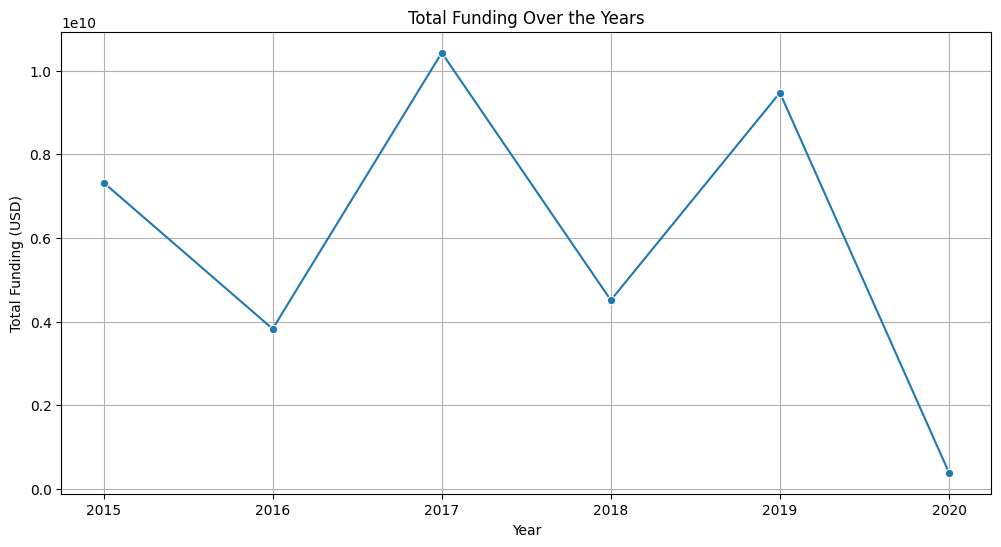

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='Year', y='Funding_USD', data=funding_by_year, marker='o')
plt.title('Total Funding Over the Years')
plt.xlabel('Year')
plt.ylabel('Total Funding (USD)')
plt.grid(True)
plt.xticks(funding_by_year['Year'].unique())
plt.show()

### Explanation:
- `plt.figure(figsize=(12, 6))`: Sets up the plot size for better readability.
- `sns.lineplot(x='Year', y='Funding_USD', data=funding_by_year, marker='o')`: Creates a line plot using Seaborn, showing `Total Funding (USD)` on the y-axis against `Year` on the x-axis. `marker='o'` adds points to each data point.
- `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)`: Sets the title and axis labels for clarity.
- `plt.grid(True)`: Adds a grid to the plot for easier interpretation of values.
- `plt.xticks(funding_by_year['Year'].unique())`: Ensures all unique years are shown as x-axis ticks.
- `plt.show()`: Displays the generated plot.

In [ ]:
funding_by_industry = df.groupby('Industry')['Funding_USD'].sum().sort_values(ascending=False).head(10).reset_index()

### Explanation:
- `funding_by_industry = df.groupby('Industry')['Funding_USD'].sum().sort_values(ascending=False).head(10).reset_index()`: This line groups the DataFrame by the `Industry` column, calculates the sum of `Funding_USD` for each industry, sorts them in descending order to get the highest funded industries, selects the top 10, and then converts the result back into a DataFrame.

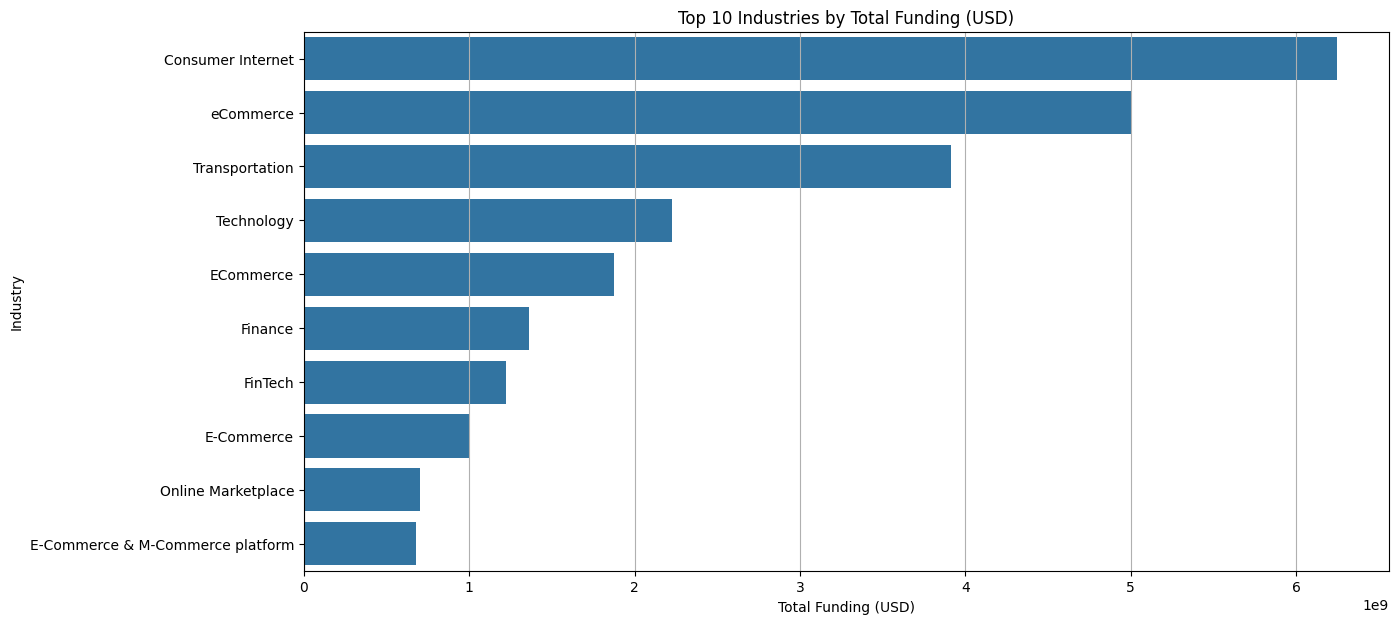

In [ ]:
plt.figure(figsize=(14, 7))
sns.barplot(x='Funding_USD', y='Industry', data=funding_by_industry)
plt.title('Top 10 Industries by Total Funding (USD)')
plt.xlabel('Total Funding (USD)')
plt.ylabel('Industry')
plt.grid(axis='x')
plt.show()

### Explanation:
- `plt.figure(figsize=(14, 7))`: Sets up the plot size.
- `sns.barplot(x='Funding_USD', y='Industry', data=funding_by_industry)`: Creates a horizontal bar plot using Seaborn, showing `Total Funding (USD)` on the x-axis and `Industry` on the y-axis for the top 10 industries.
- `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)`: Sets the title and axis labels.
- `plt.grid(axis='x')`: Adds a horizontal grid for better readability of funding amounts.
- `plt.show()`: Displays the plot.

In [ ]:
funding_by_city = df.groupby('City')['Funding_USD'].sum().sort_values(ascending=False).head(10).reset_index()

### Explanation:
- `funding_by_city = df.groupby('City')['Funding_USD'].sum().sort_values(ascending=False).head(10).reset_index()`: This line groups the DataFrame by the `City` column, calculates the sum of `Funding_USD` for each city, sorts them in descending order to get the highest funded cities, selects the top 10, and then converts the result back into a DataFrame.

In [ ]:
df.columns

Index(['Date', 'Startup_Name', 'Industry', 'Sub_Vertical', 'City', 'Investors',
       'Investment_Type', 'Funding_USD', 'amount_inr_cr', 'Year'],
      dtype='object')

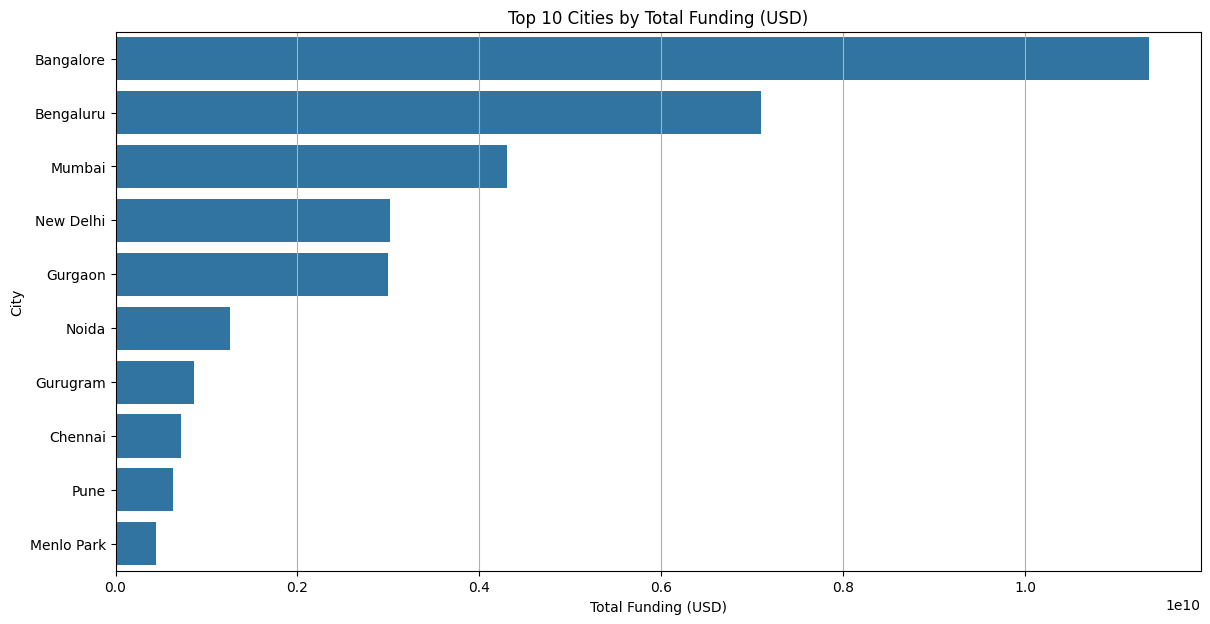

In [ ]:
plt.figure(figsize=(14, 7))
sns.barplot(x='Funding_USD', y='City', data=funding_by_city)
plt.title('Top 10 Cities by Total Funding (USD)')
plt.xlabel('Total Funding (USD)')
plt.ylabel('City')
plt.grid(axis='x')
plt.show()

### Explanation:
- `plt.figure(figsize=(14, 7))`: Sets up the plot size.
- `sns.barplot(x='Funding_USD', y='City', data=funding_by_city)`: Creates a horizontal bar plot using Seaborn, showing `Total Funding (USD)` on the x-axis and `City` on the y-axis for the top 10 cities.
- `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)`: Sets the title and axis labels.
- `plt.grid(axis='x')`: Adds a horizontal grid for better readability of funding amounts.
- `plt.show()`: Displays the plot.

In [ ]:
# Standardize Investment_Type names
df['Investment_Type'] = df['Investment_Type'].astype(str).str.lower().str.strip()
df['Investment_Type'] = df['Investment_Type'].replace({
    'seed funding': 'Seed Funding',
    'seed/ angel funding': 'Seed Funding',
    'seed / angel funding': 'Seed Funding',
    'seed/angel funding': 'Seed Funding',
    'angel / seed funding': 'Seed Funding',
    'seed round': 'Seed Funding',
    'seed': 'Seed Funding',
    'angel round': 'Seed Funding',
    'angel funding': 'Seed Funding',
    'private equity': 'Private Equity',
    'private equity round': 'Private Equity',
    'privateequity': 'Private Equity',
    'pre-series a': 'Pre-Series A',
    'pre series a': 'Pre-Series A',
    'pre-series a': 'Pre-Series A',
    'series a': 'Series A',
    'series b': 'Series B',
    'series c': 'Series C',
    'series d': 'Series D',
    'series e': 'Series E',
    'series f': 'Series F',
    'series g': 'Series G',
    'series h': 'Series H',
    'series j': 'Series J',
    'venture': 'Venture Capital',
    'venture round': 'Venture Capital',
    'debt funding': 'Debt Funding',
    'debt-funding': 'Debt Funding',
    'debt': 'Debt Funding'
})

investment_type_counts = df['Investment_Type'].value_counts().head(10).reset_index()

### Explanation:
- The `Investment_Type` column is first converted to lowercase and stripped of whitespace to ensure consistency.
- A dictionary-based replacement is then applied to group similar investment types (e.g., all variations of 'Seed Funding' become 'Seed Funding', 'private equity' variations become 'Private Equity', etc.). This standardizes the categories.
- `investment_type_counts = df['Investment_Type'].value_counts().head(10).reset_index()`: This line calculates the frequency of each standardized investment type, takes the top 10 most frequent, and stores them in a new DataFrame `investment_type_counts`.

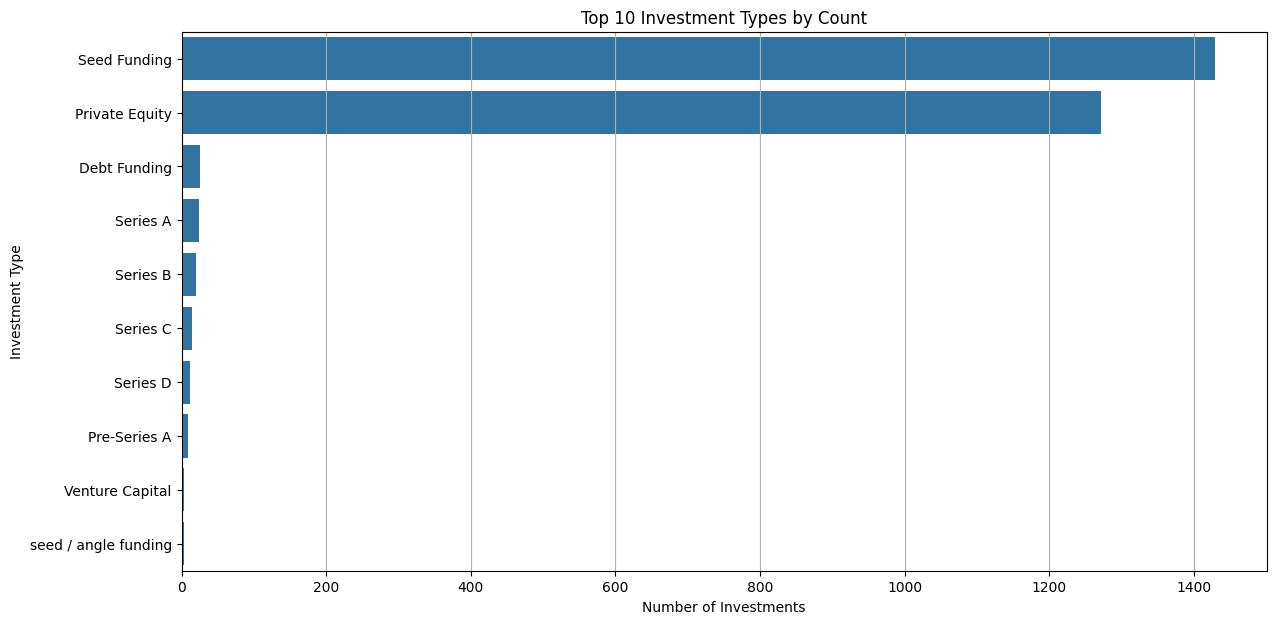

In [ ]:
plt.figure(figsize=(14, 7))
sns.barplot(x='count', y='Investment_Type', data=investment_type_counts)
plt.title('Top 10 Investment Types by Count')
plt.xlabel('Number of Investments')
plt.ylabel('Investment Type')
plt.grid(axis='x')
plt.show()

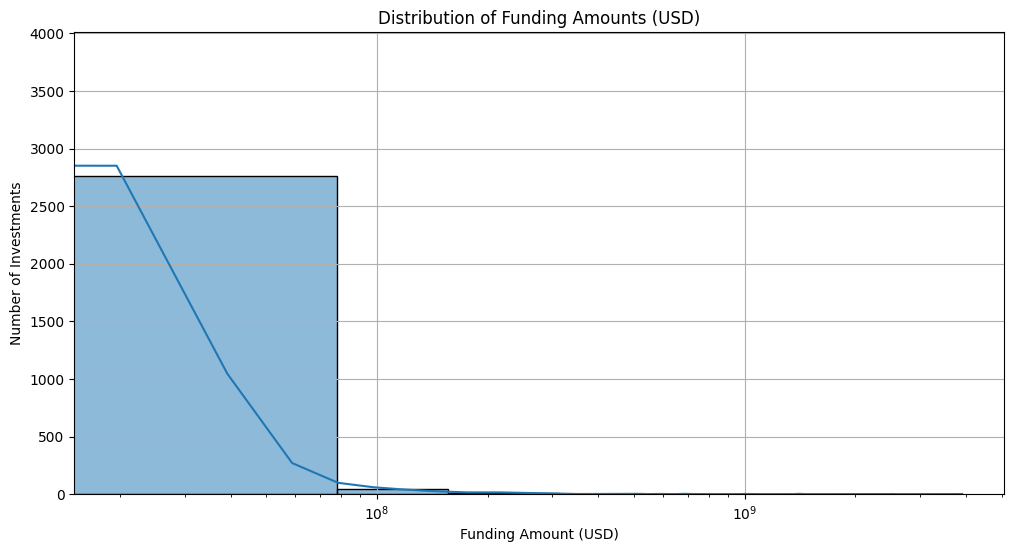

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(df['Funding_USD'], bins=50, kde=True)
plt.title('Distribution of Funding Amounts (USD)')
plt.xlabel('Funding Amount (USD)')
plt.ylabel('Number of Investments')
plt.xscale('log') # Use a log scale for better visibility due to skewed data
plt.grid(True)
plt.show()

In [ ]:
df.columns

Index(['Date', 'Startup_Name', 'Industry', 'Sub_Vertical', 'City', 'Investors',
       'Investment_Type', 'Funding_USD', 'amount_inr_cr', 'Year'],
      dtype='object')

<Axes: ylabel='Funding_USD'>

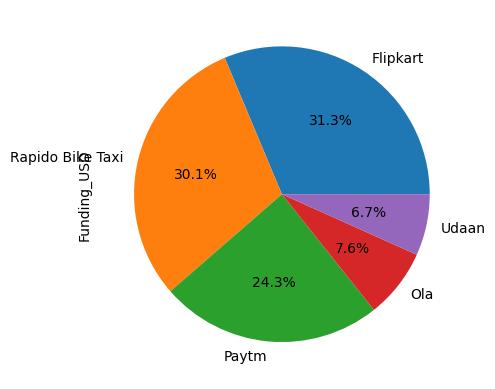

In [ ]:
df.groupby('Startup_Name')['Funding_USD'].sum().sort_values(ascending=False).head().plot(kind='pie',autopct='%1.1f%%')


## Problem Statements Solved & Conclusions

### Problem Statements Solved:

1.  **Data Ingestion and Initial Assessment**: Successfully loaded the Indian Startup Funding dataset from Kaggle and performed initial checks on its structure, data types, missing values, and duplicates.
2.  **Data Cleaning and Preprocessing**: Addressed several data quality issues:
    *   **Inconsistent Column Names**: Standardized column names for better readability and usability.
    *   **Malformated Date Entries**: Cleaned and converted the 'Date' column to a proper datetime format, handling various inconsistencies.
    *   **Missing 'Remarks' Data**: Dropped the 'Remarks' column due to a high percentage of missing values, as it offered little analytical value.
    *   **Non-numeric 'Funding_USD'**: Cleaned the 'Funding_USD' column by removing non-numeric characters (commas), replacing text values ('undisclosed', 'unknown') with zeros, and converting it to a numeric (float) type. Missing values were also imputed with zero.
    *   **Currency Conversion**: Converted USD funding amounts to Indian Rupees (crores) to provide local context, creating a new `amount_inr_cr` column.
    *   **Missing Critical Data**: Removed rows where essential columns (`Date`, `Startup_Name`, `Industry`, `City`, `Investors`, `Investment_Type`, `Funding_USD`) had missing values.
    *   **Inconsistent 'Startup_Name'**: Cleaned and standardized startup names by handling URLs, specific misspellings, and applying consistent title casing.
    *   **Missing 'Sub_Vertical' Data**: Filled missing values in the 'Sub_Vertical' column with 'Unknown' to retain data while explicitly marking its absence.
    *   **Inconsistent 'Investment_Type'**: Standardized various spellings and categories within the 'Investment_Type' column to group similar investment rounds (e.g., 'Seed Funding', 'Private Equity').
3.  **Exploratory Data Analysis (EDA)**: Explored the cleaned dataset to understand key trends and distributions in the Indian startup ecosystem, including:
    *   Overall funding trends over the years.
    *   Identification of top-funded industries.
    *   Identification of top cities attracting startup investments.
    *   Analysis of the most common investment types.
    *   Distribution of funding amounts.
    *   Identification of top-funded individual startups.

### Key Conclusions:

*   **Significant Funding Landscape**: The Indian startup ecosystem attracts substantial funding, with a wide range of investment amounts.
*   **Dominant Investment Types**: 'Seed Funding' and 'Private Equity' are the most prevalent investment types, indicating a healthy mix of early-stage and growth-stage investments.
*   **Key Sectors**: Industries such as 'Consumer Internet', 'Technology', and 'eCommerce' consistently attract the highest total funding, reflecting their prominence in the Indian market.
*   **Geographic Hubs**: Major metropolitan areas like Bangalore, Mumbai, and New Delhi serve as primary hubs for startup funding, concentrating a significant portion of investment activity.
*   **Funding Distribution Skew**: The distribution of funding amounts is highly skewed, with a few large investments significantly impacting the total funding, while a large number of startups receive smaller amounts. The median funding amount is significantly lower than the mean, highlighting this skew.
*   **Top Funded Startups**: Companies like Rapido Bike Taxi, Flipkart, and Paytm have secured some of the largest funding rounds, demonstrating their market leadership and investor confidence.